# 5B. Transfer Learning - Intel Image (MobileNetV2)

In [1]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
BASE = "../datasets/Object Detection/Intel Image Classification"
train = keras.utils.image_dataset_from_directory(
    BASE, image_size=(128, 128), validation_split=0.2, subset="training", seed=42)
val = keras.utils.image_dataset_from_directory(
    BASE, image_size=(128, 128), validation_split=0.2, subset="validation", seed=42)

class_names = train.class_names
n_classes = len(class_names)
print("classes:", train.class_names)

train = train.prefetch(2)
val = val.prefetch(2)

Found 12632 files belonging to 6 classes.


Using 10106 files for training.


Found 12632 files belonging to 6 classes.


Using 2526 files for validation.


classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [3]:
base = keras.applications.MobileNetV2(include_top=False, input_shape=(128, 128, 3))
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,358 (8.93 MB)

 Trainable params: 82,374 (321.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [4]:
history = model.fit(train, validation_data=val, epochs=3)

Epoch 1/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 37s 111ms/step - accuracy: 0.8835 - loss: 0.3185 - val_accuracy: 0.9145 - val_loss: 0.2373
Epoch 2/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 41s 129ms/step - accuracy: 0.9276 - loss: 0.1934 - val_accuracy: 0.9177 - val_loss: 0.2276
Epoch 3/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 33s 105ms/step - accuracy: 0.9474 - loss: 0.1444 - val_accuracy: 0.9141 - val_loss: 0.2425


In [5]:
loss, acc = model.evaluate(val)
print(f"val acc: {acc:.4f}")

 1/79 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.9062 - loss: 0.2877

 2/79 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step - accuracy: 0.9375 - loss: 0.1760

 3/79 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - accuracy: 0.9375 - loss: 0.1986

 4/79 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.9219 - loss: 0.2908

 5/79 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.9312 - loss: 0.2794

 6/79 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.9167 - loss: 0.2786

... (71 outputs left out)

78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9135 - loss: 0.2433

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9141 - loss: 0.2425

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.9141 - loss: 0.2425


val acc: 0.9141


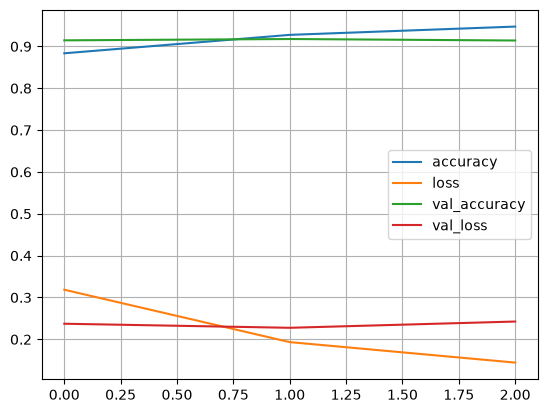

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()

## h. Visualize predictions

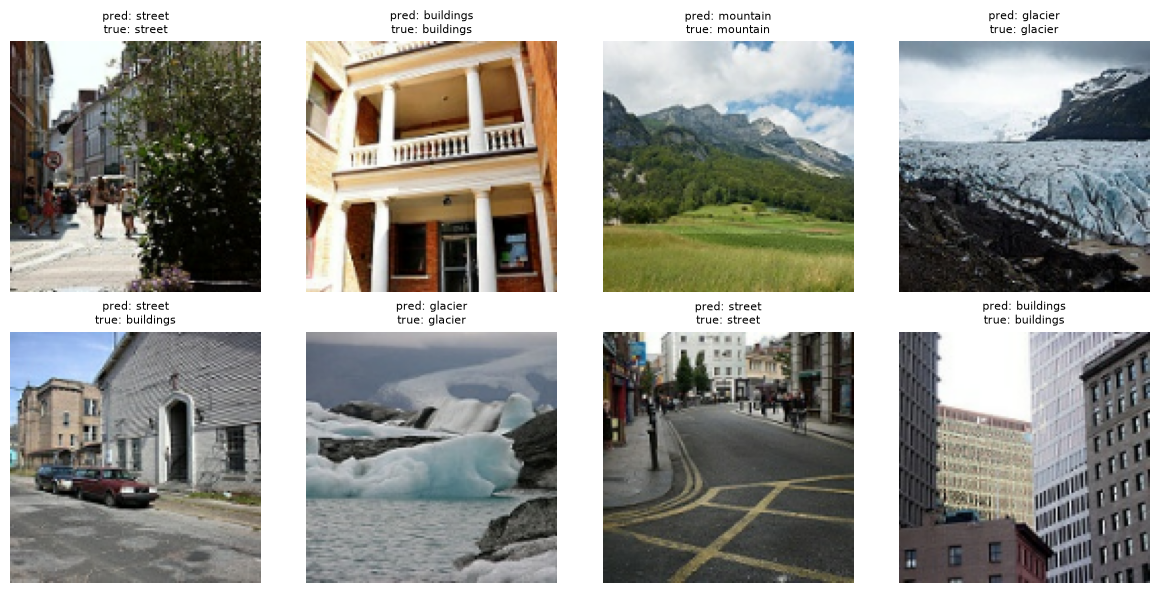

In [7]:
for images, labels in val.take(1):
    preds = model.predict(images)
    pred_classes = preds.argmax(axis=1)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"pred: {class_names[pred_classes[i]]}\ntrue: {class_names[labels[i].numpy()]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## i. Fine-tune
Unfreeze the top layers of the pretrained base, recompile with a much smaller learning rate (1e-5), retrain for 2 epochs.

In [8]:
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(train, validation_data=val, epochs=2)

Epoch 1/2


  1/316 ━━━━━━━━━━━━━━━━━━━━ 12:39 2s/step - accuracy: 0.9375 - loss: 0.2195

  2/316 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - accuracy: 0.9219 - loss: 0.2791

  3/316 ━━━━━━━━━━━━━━━━━━━━ 28s 91ms/step - accuracy: 0.9271 - loss: 0.2502

  4/316 ━━━━━━━━━━━━━━━━━━━━ 27s 89ms/step - accuracy: 0.9141 - loss: 0.2867

  5/316 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.8938 - loss: 0.3780

... (626 outputs left out)

314/316 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9485 - loss: 0.1418

315/316 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9486 - loss: 0.1416

316/316 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9486 - loss: 0.1415

316/316 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.9486 - loss: 0.1415 - val_accuracy: 0.9169 - val_loss: 0.2515


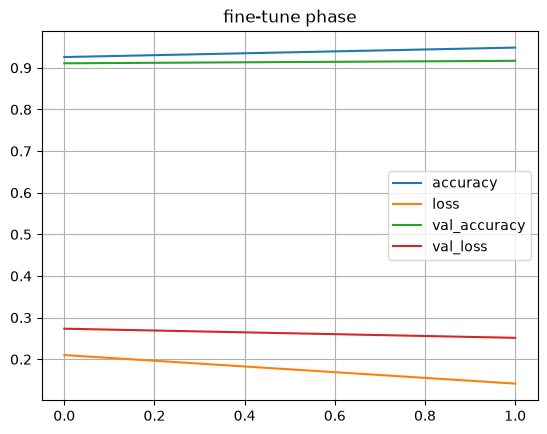

In [9]:
for k, v in history_ft.history.items():
    plt.plot(v, label=k)
plt.title("fine-tune phase")
plt.legend()
plt.grid()
plt.show()